# Piezas movidas por día por área — API LISA (SGA)

Serie diaria del volumen movido en cada área del almacén, tomando **cada endpoint SGA como un área**:

| Endpoint | Área | Campo de piezas | Métrica graficada |
|---|---|---|---|
| `SGAENTRADAS` | Entradas (recepción) | — *no existe* | **tareas/día** (proxy) |
| `SGACOLOCACION2` | Colocación (ubicación) | `unidades1` | **piezas/día** |
| `SGAPREPARACION2` | Preparación (surtido) | `cantidad_p` | **piezas/día** |
| `SGAEMBALAJE` | Embalaje | — *no existe* | **tareas/día** (proxy) |

> **Limitación del API (verificada contra la unión de campos de las respuestas):** `sga_entradas` y
> `sga_embalaje` no devuelven ningún campo de cantidad (`cant*`, `unidades*`, `piezas*`), por lo que en
> esas dos áreas se grafica el **número de tareas por día** como proxy de volumen, etiquetado como tal.
> `sga_colocacion_2` trae `unidades1` (= `cant_pres`) por tarea y `sga_preparacion_2` ya viene agregado
> por usuario/día con `cantidad_p` (= `cantidad_1`).

Notas de importación:

- Los filtros de fecha actúan como **cota inferior**: una fecha temprana trae toda la historia en una llamada.
- `sga_preparacion_2` filtra por `p_fecha_tarea` (no `p_fecha_gen`).
- La base temporal es `fecha_inicio` (inicio de la tarea en el handheld, convención del repo); en
  `sga_preparacion_2` se usa `fecha`, que ya es diaria.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from lisa_client import LisaClient

ALMACEN = "5460D"
FECHA_DESDE = "01/01/2025"  # cota inferior: trae toda la historia disponible

client = LisaClient()

## 1. Importación desde el API

Los registros vienen en `registros.reg` (un `dict` cuando hay un solo registro, una lista en otro caso).

In [2]:
def a_dataframe(respuesta: dict) -> pd.DataFrame:
    """Convierte la respuesta del API (registros.reg) en un DataFrame."""
    registros = (respuesta.get("registros") or {}).get("reg") or []
    if isinstance(registros, dict):  # un solo registro llega como dict
        registros = [registros]
    return pd.DataFrame(registros)


df_entradas = a_dataframe(client.entradas_almacen(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_colocacion = a_dataframe(client.colocacion_2(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_preparacion = a_dataframe(client.preparacion_2(fecha_tarea=FECHA_DESDE, almacen=ALMACEN))
df_embalaje = a_dataframe(client.embalaje(fecha_gen=FECHA_DESDE, almacen=ALMACEN))

for nombre, df in [
    ("SGAENTRADAS", df_entradas),
    ("SGACOLOCACION2", df_colocacion),
    ("SGAPREPARACION2", df_preparacion),
    ("SGAEMBALAJE", df_embalaje),
]:
    print(f"{nombre:16s} {len(df):>7,} registros · {df.shape[1]} columnas")

19:36:50 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


19:36:54 [INFO] POST /galileo/lisa/geninf/isp/sga_colocacion_2 | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


19:37:03 [INFO] POST /galileo/lisa/geninf/isp/sga_preparacion_2 | body: {'p_fecha_tarea': '01/01/2025', 'p_almacen': '5460D'}


19:37:06 [INFO] POST /galileo/lisa/geninf/isp/sga_embalaje | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


SGAENTRADAS        3,405 registros · 34 columnas
SGACOLOCACION2     7,365 registros · 54 columnas
SGAPREPARACION2    1,933 registros · 16 columnas
SGAEMBALAJE       15,593 registros · 33 columnas


## 2. Serie diaria por área

Se agrupa por día natural y los días sin registros dentro del rango observado quedan en **0**
(no se movió nada: fines de semana / festivos). Los registros sin fecha de inicio (tareas aún no
iniciadas) se descartan y se contabilizan en el resumen.

In [3]:
def serie_diaria(df: pd.DataFrame, col_fecha: str, col_piezas: str | None = None):
    """Serie por día natural: suma de `col_piezas`, o conteo de tareas si es None.

    Devuelve (serie, registros_sin_fecha_descartados).
    """
    fechas = pd.to_datetime(df[col_fecha], format="mixed", dayfirst=True, errors="coerce")
    validos = fechas.notna()
    if col_piezas is None:
        valores = pd.Series(1, index=df.index)
    else:
        valores = pd.to_numeric(df[col_piezas], errors="coerce").fillna(0)
    s = valores[validos].groupby(fechas[validos].dt.normalize()).sum().sort_index()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"), fill_value=0)
    return s, int((~validos).sum())


# Paleta categórica en orden fijo (validada para visión de color y contraste)
AREAS = {}
for nombre, df, col_fecha, col_piezas, color, nota in [
    ("Entradas (SGAENTRADAS)", df_entradas, "fecha_inicio", None, "#2a78d6",
     "proxy: el endpoint no expone piezas"),
    ("Colocación (SGACOLOCACION2)", df_colocacion, "fecha_inicio", "unidades1", "#1baf7a", ""),
    ("Preparación (SGAPREPARACION2)", df_preparacion, "fecha", "cantidad_p", "#eda100", ""),
    ("Embalaje (SGAEMBALAJE)", df_embalaje, "fecha_inicio", None, "#008300",
     "proxy: el endpoint no expone piezas"),
]:
    serie, descartados = serie_diaria(df, col_fecha, col_piezas)
    AREAS[nombre] = {
        "serie": serie,
        "metrica": "piezas/día" if col_piezas else "tareas/día",
        "color": color,
        "nota": nota,
        "descartados": descartados,
    }

## 3. Resumen por área (vista de tabla)

In [4]:
resumen = pd.DataFrame(
    [
        {
            "área": nombre,
            "métrica": a["metrica"],
            "desde": a["serie"].index.min().date(),
            "hasta": a["serie"].index.max().date(),
            "días con actividad": int((a["serie"] > 0).sum()),
            "total": int(a["serie"].sum()),
            "promedio/día activo": round(a["serie"][a["serie"] > 0].mean(), 1),
            "máximo diario": int(a["serie"].max()),
            "sin fecha (descartados)": a["descartados"],
        }
        for nombre, a in AREAS.items()
    ]
).set_index("área")
resumen

,métrica,desde,hasta,días con actividad,total,promedio/día activo,máximo diario,sin fecha (descartados)
área,,,,,,,,
Entradas (SGAENTRADAS),tareas/día,2026-01-02,2026-06-26,111,3405,30.7,114,0
Colocación (SGACOLOCACION2),piezas/día,2026-01-05,2026-07-06,124,9163600,73900.0,333655,16
Preparación (SGAPREPARACION2),piezas/día,2026-02-09,2026-04-10,44,2487163,56526.4,113912,0
Embalaje (SGAEMBALAJE),tareas/día,2026-02-09,2026-07-07,110,15450,140.5,501,143


In [5]:
# Tabla diaria completa (una columna por área) — últimos 10 días con datos de alguna área
tabla_diaria = pd.DataFrame(
    {f"{nombre} [{a['metrica']}]": a["serie"] for nombre, a in AREAS.items()}
)
tabla_diaria.index.name = "fecha"
tabla_diaria.tail(10)

,Entradas (SGAENTRADAS) [tareas/día],Colocación (SGACOLOCACION2) [piezas/día],Preparación (SGAPREPARACION2) [piezas/día],Embalaje (SGAEMBALAJE) [tareas/día]
fecha,,,,
2026-06-28,NaN,0.0,NaN,0.0
2026-06-29,NaN,378.0,NaN,168.0
2026-06-30,NaN,0.0,NaN,188.0
2026-07-01,NaN,1537.0,NaN,135.0
2026-07-02,NaN,1253.0,NaN,255.0
2026-07-03,NaN,0.0,NaN,115.0
2026-07-04,NaN,750.0,NaN,0.0
2026-07-05,NaN,0.0,NaN,0.0
2026-07-06,NaN,5320.0,NaN,209.0


## 4. Volumen diario por área

Un subplot por área, con el eje de fechas compartido para comparar los periodos con datos
(p. ej. `sga_preparacion_2` deja de reportar antes que las demás áreas — el corte es visible).
Las escalas verticales son independientes porque las métricas difieren (piezas vs. tareas).

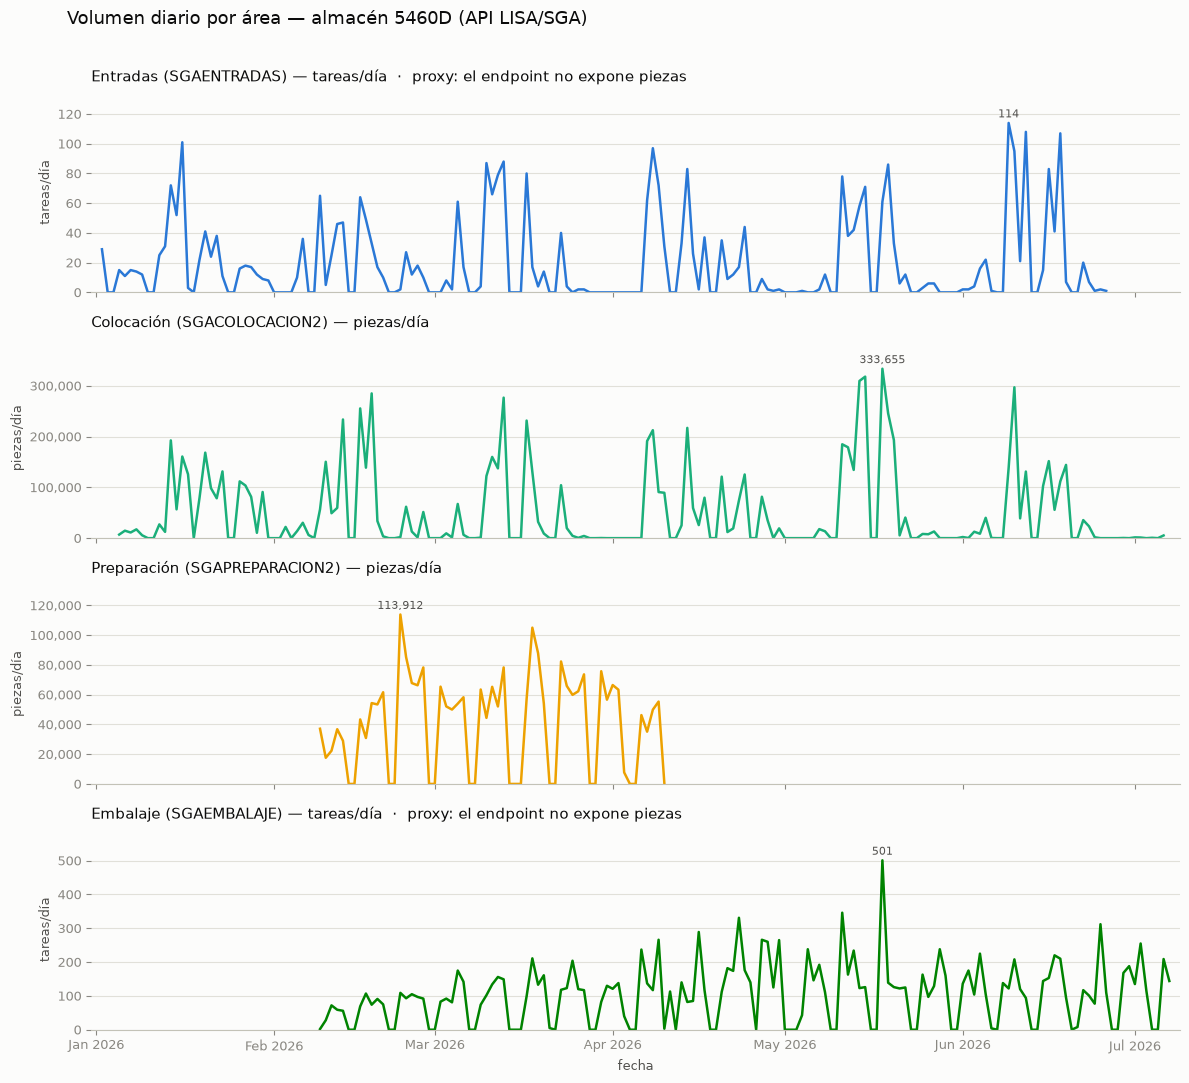

In [6]:
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

fmt_miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

fig, axes = plt.subplots(len(AREAS), 1, figsize=(12, 11), sharex=True)
fig.patch.set_facecolor(SURFACE)

for ax, (nombre, a) in zip(axes, AREAS.items()):
    s = a["serie"]
    ax.plot(s.index, s.values, color=a["color"], linewidth=1.8)

    titulo = f"{nombre} — {a['metrica']}"
    if a["nota"]:
        titulo += f"  ·  {a['nota']}"
    ax.set_title(titulo, loc="left", fontsize=11, color=INK, pad=8)

    ax.set_facecolor(SURFACE)
    ax.set_ylabel(a["metrica"], fontsize=9, color=INK_2)
    ax.set_ylim(0, s.max() * 1.18)
    ax.margins(x=0.01)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.yaxis.set_major_formatter(fmt_miles)

    # etiqueta directa del pico
    dia_max = s.idxmax()
    ax.annotate(
        f"{int(s.max()):,}",
        xy=(dia_max, s.max()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=INK_2,
    )

axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("fecha", fontsize=9, color=INK_2)

fig.suptitle(
    f"Volumen diario por área — almacén {ALMACEN} (API LISA/SGA)",
    fontsize=13,
    color=INK,
    x=0.06,
    ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()